# LiDAR 단일 스캔 지도 (위에서 본 점 지도)

로봇을 움직이지 않고 LiDAR로 한 번 스캔해, 주변 벽과 물체를 위에서 본 점 지도로 그립니다.

## 하는 일
- 5회전 분의 측정을 모아 1° 단위로 거리의 중앙값을 구하고, 6m 이내의 점만 사용합니다.
- 앞을 위쪽(+y), 오른쪽을 +x로 하고 LiDAR(빨간 삼각형)를 원점에 그립니다. (0°=앞, 90°=오른쪽. 4방향 노트북에서 확인한 규약)
- 스캔 시작이 실패하면 재시도합니다 (이전 노트북과 동일).

## 결과
- 유효한 각도: 349/360
- 방향별 거리 (±3° 중앙값)

| 방향 | LiDAR (mm) | 줄자 (mm) |
|---|---|---|
| 앞 | 402 | ___ |
| 오른쪽 | 5644 | ___ |
| 뒤 | 1439 | ___ |
| 왼쪽 | 4024 | ___ |

## 한계
- 정지 상태의 한 위치에서 한 번 찍은 점 지도입니다. 점유 격자나 SLAM이 아닙니다.
- LiDAR는 바닥에서 약 13cm 높이(강의 자료 기준)의 한 평면만 봅니다. 그보다 낮은 물체나 유리·거울은 잘 보이지 않습니다.
- 11개 각도는 값이 없었습니다.

유효한 각도: 349/360
앞: 402 mm
오른쪽: 5644 mm
뒤: 1439 mm
왼쪽: 4024 mm


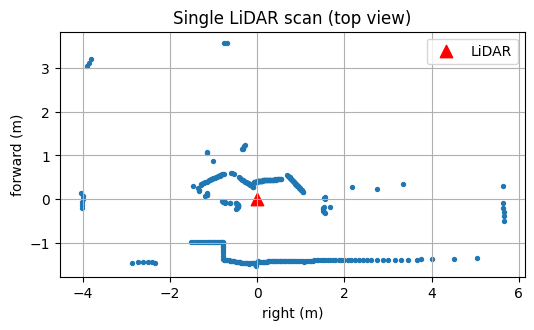

In [1]:
import math
import time
import statistics
from collections import defaultdict
from rplidar import RPLidar, RPLidarException
import matplotlib.pyplot as plt

PORT = '/dev/ttyUSB0'
BAUDRATE = 460800
N_REVOLUTIONS = 5       # 이 횟수만큼 회전한 스캔을 모아 각도별 중앙값 사용
MAX_RANGE_MM = 6000     # 이보다 먼 점은 제외
OUT_PNG = 'lidar_single_scan.png'


def measures_with_retry(lidar, retries=5):
    for attempt in range(1, retries + 1):
        gen = lidar.iter_measures()
        try:
            first = next(gen)
        except RPLidarException as e:
            print(f"스캔 시작 실패 ({attempt}/{retries}): {e}")
            try:
                lidar.stop()
            except Exception:
                pass
            time.sleep(1.0)
            continue
        yield first
        yield from gen
        return
    raise RuntimeError("LiDAR 스캔 시작에 계속 실패했습니다")


def collect_scan(lidar, n_rev):
    """n_rev번 회전하는 동안 1도 단위로 거리를 모은다."""
    bins = defaultdict(list)
    revs = 0
    for new_scan, quality, angle, distance in measures_with_retry(lidar):
        if new_scan:                     # 새 회전의 시작 표시
            revs += 1
            if revs > n_rev:
                break
        if revs >= 1 and distance > 0:
            bins[int(angle) % 360].append(distance)
    return bins


def direction_mm(bins, center, half=3):
    vals = []
    for k in range(center - half, center + half + 1):
        vals += bins.get(k % 360, [])
    return statistics.median(vals) if vals else None


lidar = RPLidar(PORT, baudrate=BAUDRATE, timeout=2)
try:
    bins = collect_scan(lidar, N_REVOLUTIONS)
finally:
    for fn in (lidar.stop, lidar.stop_motor, lidar.disconnect):
        try:
            fn()
        except Exception:
            pass

# 각도별 중앙값 -> 점 목록
points = []
for deg in sorted(bins):
    d = statistics.median(bins[deg])
    if d <= MAX_RANGE_MM:
        points.append((deg, d))
print(f"유효한 각도: {len(points)}/360")

# 실측 비교용 4방향 거리
for name, center in (("앞", 0), ("오른쪽", 90), ("뒤", 180), ("왼쪽", 270)):
    v = direction_mm(bins, center)
    print(f"{name}: {v:.0f} mm" if v else f"{name}: ---")

# 위에서 본 지도: 앞이 위쪽(+y), 오른쪽이 오른쪽(+x)
xs = [d / 1000 * math.sin(math.radians(a)) for a, d in points]
ys = [d / 1000 * math.cos(math.radians(a)) for a, d in points]

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xs, ys, s=8)
ax.scatter([0], [0], c='red', marker='^', s=80, label='LiDAR')
ax.set_aspect('equal')
ax.grid(True)
ax.set_xlabel('right (m)')
ax.set_ylabel('forward (m)')
ax.set_title('Single LiDAR scan (top view)')
ax.legend()
plt.savefig(OUT_PNG, dpi=150)
plt.show()

In [2]:
valid = {a for a, d in points}
missing = sorted(set(range(360)) - valid)
print(missing)

[86, 103, 104, 106, 108, 244, 260, 282, 283, 314, 318]
